In [1]:
!pip install kaleido==0.1.*

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 MB 25.7 MB/s eta 0:00:00:00:0100:01


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader,Dataset
from torchvision.utils import make_grid
import torch.nn as nn
import torchmetrics
from torchvision import datasets,models
from tqdm.notebook import tqdm

In [21]:
def load_data(PATH):
    images,labels,fruits = [], [],[]
    for file in tqdm(os.listdir(PATH)):
        for img in os.listdir(os.path.join(PATH, file)):
            labels.append(0 if file[0] == 'f' else 1)
            if file[0] == 'f':
                fruits.append(file[5:])
            else:
                fruits.append(file[6:])
            images.append(os.path.join(PATH, file, img))
    df = pd.DataFrame({
        'images' : images,
        'labels' : labels,
        'fruits': fruits
    })
    return df
    
data_dir = '/kaggle/input/datasets/swoyam2609/fresh-and-stale-classification/dataset/'
train_df = load_data(data_dir+'/Train')
test_df = load_data(data_dir+'/Test')

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

In [22]:
train_df.shape,test_df.shape

((23619, 3), (6738, 3))

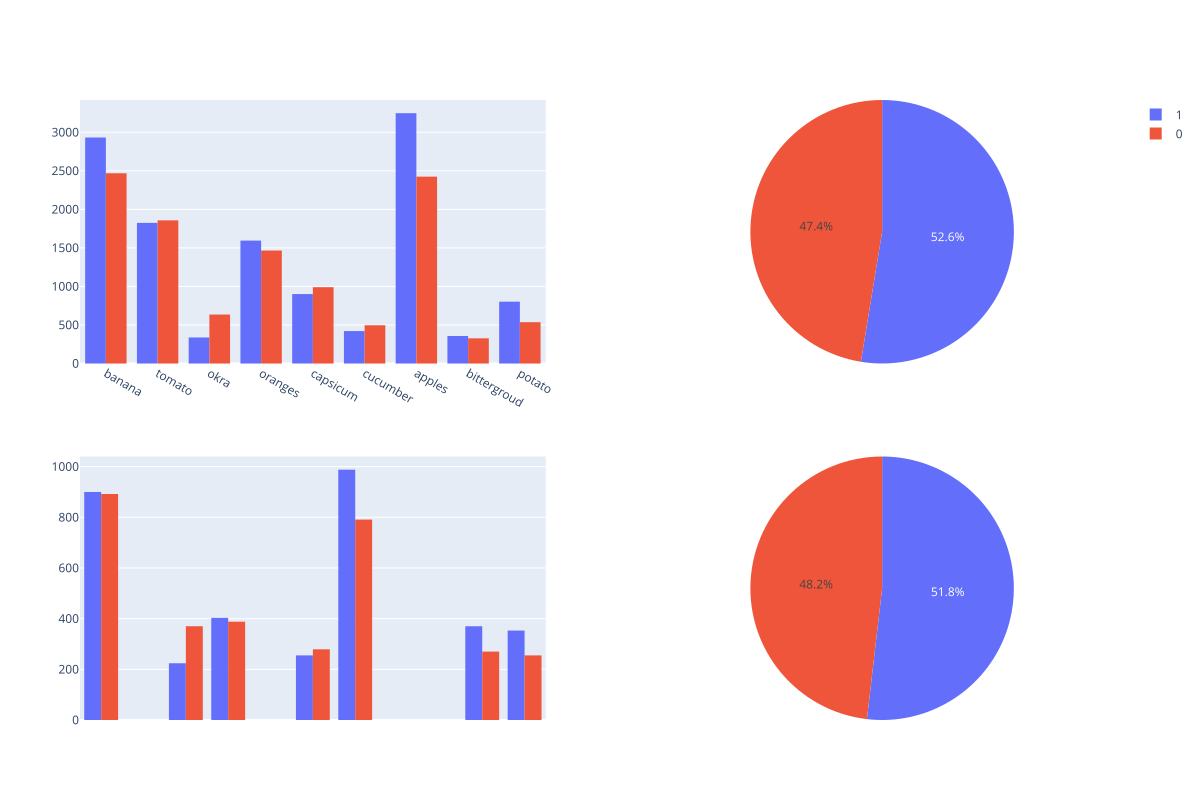

In [5]:
import plotly.express as px
from plotly.subplots import make_subplots
fig = make_subplots(rows=2,cols=2,specs=[[{'type':'xy'},{'type':'pie'}],[{'type':'xy'},{'type':'pie'}]])
sub = px.histogram(train_df,x='fruits',color='labels',barmode='group')
sub.update_traces(showlegend=False)
for trace in sub.data:
    fig.add_trace(trace,row=1,col=1) 
vcdf = train_df['labels'].value_counts().reset_index()
for trace in px.pie(vcdf,names='labels',values='count').data:
    fig.add_trace(trace,row=1,col=2)
sub = px.histogram(test_df,x='fruits',color='labels',barmode='group')
sub.update_traces(showlegend=False)
for trace in sub.data:
    fig.add_trace(trace,row=2,col=1) 
vcdf = test_df['labels'].value_counts().reset_index()
for trace in px.pie(vcdf,names='labels',values='count').data:
    fig.add_trace(trace,row=2,col=2)
fig.update_layout({'width':1200,'height':800})
fig.show('svg')

In [6]:
from PIL import Image
from torchvision.models import ResNet18_Weights as weights
transforms = weights.DEFAULT.transforms(antialias=True)
class FoodDataset(Dataset):
    def __init__(self,df):
        self.df = df
        self.n_samples = len(self.df)
        self.shape = self.df.shape

    def __len__(self):
        return self.n_samples

    def __getitem__(self,idx):
        image = Image.open(self.df.at[idx,'images']).convert('RGB')
        image = transforms(image)
        label = self.df.at[idx,'labels']
        return image,label

## Classifying Rotten Bananas from Fresh Bananas using ResNet18

In [ ]:
banana_train = train_df.loc[train_df['fruits']=='banana'].reset_index()
banana_test = test_df.loc[test_df['fruits']=='banana'].reset_index()

### Training Set Visualization

In [ ]:
plt.figure(figsize=(12,4))
for idx,img in enumerate(banana_train.tail()['images']):
    plt.subplot(1,10,idx+1)
    plt.imshow(plt.imread(img))
    plt.axis('off')
print("Fresh:",banana_train.tail()['labels'].unique())
for idx,img in enumerate(banana_train.head()['images']):
    plt.subplot(1,10,5+idx+1)
    plt.imshow(plt.imread(img))
    plt.axis('off')
print("Rotten:",banana_train.head()['labels'].unique())

### Testing Set Visualization

In [ ]:
plt.figure(figsize=(12,4))
for idx,img in enumerate(banana_test.tail()['images']):
    plt.subplot(1,10,idx+1)
    plt.imshow(plt.imread(img))
    plt.axis('off')
print("Fresh:",banana_test.tail()['labels'].unique())
for idx,img in enumerate(banana_test.head()['images']):
    plt.subplot(1,10,5+idx+1)
    plt.imshow(plt.imread(img))
    plt.axis('off')
print("Rotten:",banana_test.head()['labels'].unique())

In [ ]:
train = FoodDataset(banana_train)
test = FoodDataset(banana_test)

In [13]:
BATCH_SIZE = 64
train_loader = DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
test_loader = DataLoader(test,batch_size=BATCH_SIZE,shuffle=True) 

In [ ]:
train.shape,test.shape

In [7]:
def imshow(inp):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    plt.pause(0.001) 

inputs,classes = next(iter(train_loader))
out = make_grid(inputs)

imshow(out)

NameError: name 'train_loader' is not defined

In [16]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [7]:
import math
class Model(nn.Module):
    def __init__(self,base):
        super().__init__()
        self.alpha = 0.7
        self.base = base
        for param in list(self.base.parameters())[:-15]:
            param.requires_grad=False
        self.base.classifier = nn.Sequential()
        self.base.fc = nn.Sequential()
        self.block1 = nn.Sequential(
            nn.Linear(512,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,128),
        )
        self.block2 = nn.Sequential(
            nn.Linear(128,32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32,2),
        )
        self.optimizer1 = torch.optim.Adam([
            {"params":self.base.parameters(),'lr':1e-5},
            {"params":self.block1.parameters(),'lr':3e-4}
        ])
        self.optimizer2 = torch.optim.Adam(self.block2.parameters(),lr=3e-4)
        self.loss_fxn = nn.CrossEntropyLoss()
        self.accuracy = torchmetrics.Accuracy(task='multiclass',num_classes=2)
        self.TRAIN_BATCHES = math.ceil(len(train)/BATCH_SIZE)
        self.VAL_BATCHES = math.ceil(len(test)/BATCH_SIZE)
        self.history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}

    def forward(self,x):
        x = self.base(x)
        x = self.block1(x)
        y = self.block2(x)
        return y

    def train_step(self,x,y):
        pred = self.forward(x)
        l = self.loss_fxn(pred,y)
        self.optimizer2.zero_grad()
        self.optimizer1.zero_grad()
        l.backward(retain_graph=True)
        loss = self.alpha*l
        loss.backward()
        self.optimizer2.step()
        self.optimizer1.step()
        accuracy = self.accuracy(torch.argmax(pred,axis=1),y)
        return loss,accuracy
                           

    def val_step(self,x,y):
        with torch.no_grad():
            pred = self.forward(x)
            loss = self.alpha*self.loss_fxn(pred,y)
            accuracy = self.accuracy(torch.argmax(pred,axis=1),y)
            return loss,accuracy

    def update_history(self,train_loss,val_loss,train_acc,val_acc):
        self.history['train_loss'].append(train_loss)
        self.history['val_loss'].append(val_loss)
        self.history['train_acc'].append(train_acc)        
        self.history['val_acc'].append(val_acc)

    def train(self,epochs=5):
        for epoch in tqdm(range(epochs)):
            train_loss,train_acc = 0,0
            val_loss,val_acc = 0,0
            for X,y in tqdm(train_loader):
                X,y = [v.to(device) for v in (X,y)]
                loss,acc = self.train_step(X,y)
                train_loss+=loss.item()
                train_acc+=acc.item()
            for X,y in tqdm(test_loader):
                X,y = [v.to(device) for v in (X,y)]
                loss,acc = self.val_step(X,y)
                val_loss+=loss.item()
                val_acc+=acc.item()
            train_loss,train_acc=[x/self.TRAIN_BATCHES for x in (train_loss,train_acc)]
            val_loss,val_acc=[x/self.VAL_BATCHES for x in (val_loss,val_acc)]
            self.update_history(train_loss,val_loss,train_acc,val_acc)
            print(f'Epoch:{epoch+1}\nTraining:[loss:{train_loss:.4f},accuracy:{train_acc*100:.3f}],\n Validation:[loss:{val_loss:.4f},accuracy:{val_acc*100:.3f}]')

In [16]:
model = Model(models.resnet18(weights='IMAGENET1K_V1')).to(device)

In [ ]:
model.train(epochs=3)

In [ ]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

In [ ]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)

<Axes: >

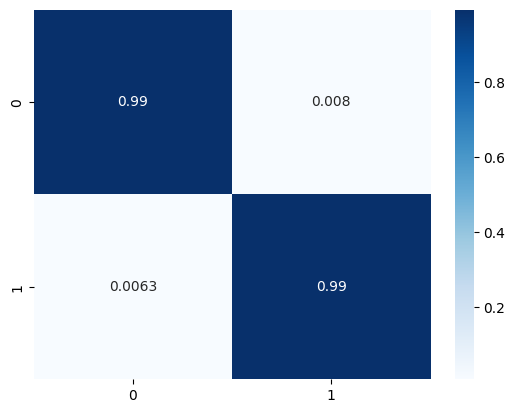

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

In [ ]:
# Utility Function to classify any fruit 
def classify_fruit(fruit_name):
    train_loader = DataLoader(FoodDataset(train_df.loc[train_df['fruits']==fruit_name].reset_index()),batch_size=BATCH_SIZE,shuffle=True)
    test_loader = DataLoader(FoodDataset(test_df.loc[test_df['fruits']==fruit_name].reset_index()),batch_size=BATCH_SIZE,shuffle=True)
    inputs,classes = next(iter(train_loader))
    imshow(make_grid(inputs))
    model.train()
    fig = plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.title("Loss")
    plt.plot(model.history['train_loss'],label="Training")
    plt.plot(model.history['val_loss'],label="Validation")
    plt.legend()
    plt.subplot(1,2,2)
    plt.title("Accuracy")
    plt.plot(model.history['train_acc'],label="Training")
    plt.plot(model.history['val_acc'],label="Validation")
    plt.legend()
    plt.show()
    y_true=[]
    y_pred=[]
    with torch.no_grad():
        for X,y in tqdm(test_loader):
            pred = model(X.to(device))
            pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
            y_true.extend(y)
            y_pred.extend(pred)
    sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

## Classifying all items as Rotten or Fresh

In [13]:
train=FoodDataset(train_df)
test=FoodDataset(test_df)
train_loader = DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
test_loader = DataLoader(test,batch_size=BATCH_SIZE,shuffle=True) 

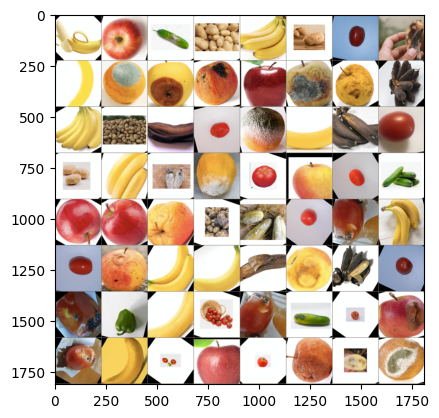

In [14]:
inputs,classes = next(iter(train_loader))
imshow(make_grid(inputs))

## Resnet18 Training

In [17]:
model.train()

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:1
Training:[loss:0.1306,accuracy:92.553],
 Validation:[loss:0.0749,accuracy:96.004]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch:4
Training:[loss:0.0203,accuracy:98.999],
 Validation:[loss:0.0192,accuracy:99.204]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:5
Training:[loss:0.0196,accuracy:99.155],
 Validation:[loss:0.0134,accuracy:99.440]


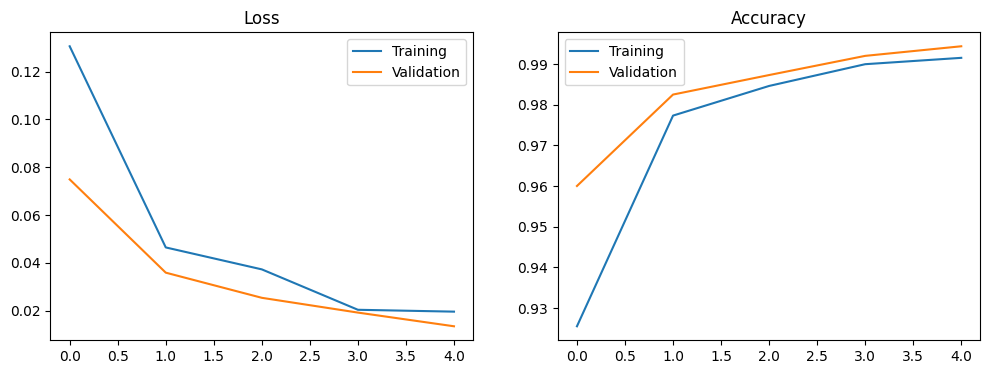

In [18]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

  0%|          | 0/106 [00:00<?, ?it/s]

<Axes: >

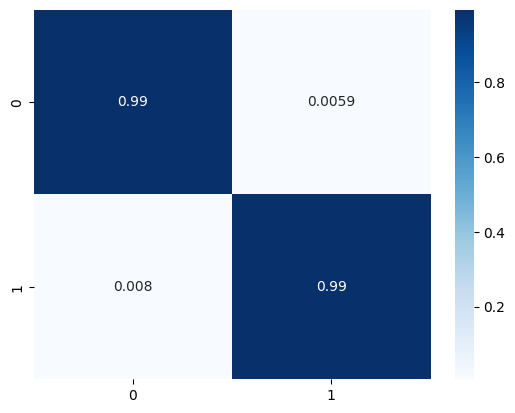

In [21]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

## Resnet34 Training

In [46]:
model = Model(models.resnet34(weights='IMAGENET1K_V1')).to(device)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 152MB/s] 


In [48]:
model.train()

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:1
Training:[loss:0.0174,accuracy:99.116],
 Validation:[loss:0.0251,accuracy:98.804]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch:4
Training:[loss:0.0115,accuracy:99.455],
 Validation:[loss:0.0102,accuracy:99.505]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:5
Training:[loss:0.0062,accuracy:99.742],
 Validation:[loss:0.0123,accuracy:99.564]


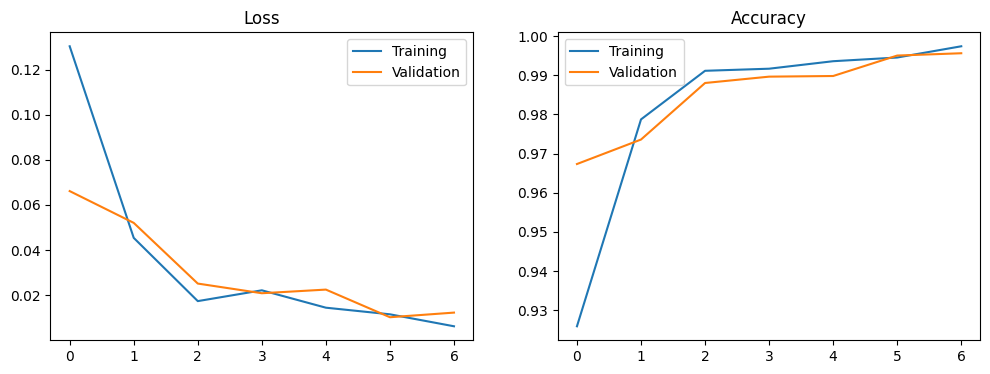

In [49]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

  0%|          | 0/106 [00:00<?, ?it/s]

<Axes: >

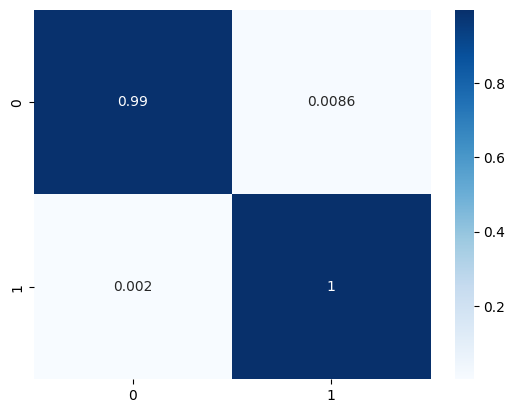

In [50]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

## Resnet50 Training

In [8]:
from torchvision.models import ResNet50_Weights as weights
transforms = weights.DEFAULT.transforms(antialias=True)
class Res50(Model):
    def __init__(self,base):
        super().__init__(base)
        self.block1 = nn.Sequential(
            nn.Linear(2048,512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512,256),
        )
        self.block2 = nn.Sequential(
            nn.Linear(256,64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64,2),
        )
        

In [42]:
model = Res50(models.resnet50(weights='IMAGENET1K_V1')).to(device)

In [24]:
train=FoodDataset(train_df)
test=FoodDataset(test_df)
train_loader = DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
test_loader = DataLoader(test,batch_size=BATCH_SIZE,shuffle=True) 

In [43]:
model.train()

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:1
Training:[loss:0.4048,accuracy:81.429],
 Validation:[loss:0.3394,accuracy:89.526]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch:4
Training:[loss:0.2595,accuracy:97.040],
 Validation:[loss:0.2552,accuracy:96.896]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:5
Training:[loss:0.2458,accuracy:97.736],
 Validation:[loss:0.2431,accuracy:96.955]


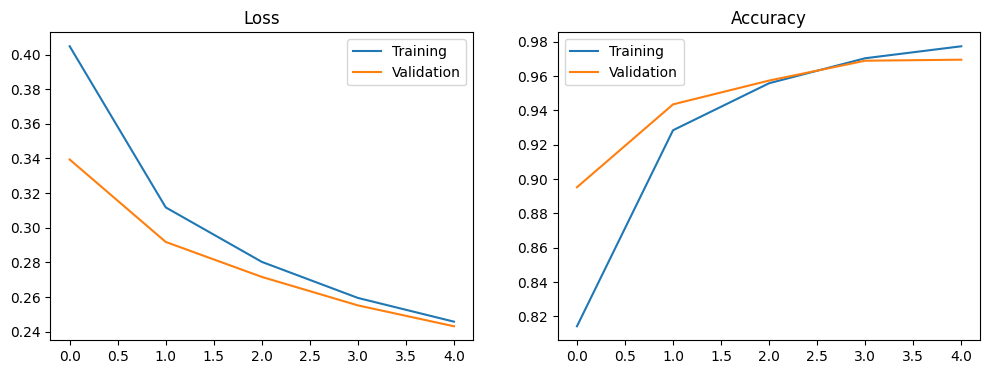

In [44]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

  0%|          | 0/106 [00:00<?, ?it/s]

<Axes: >

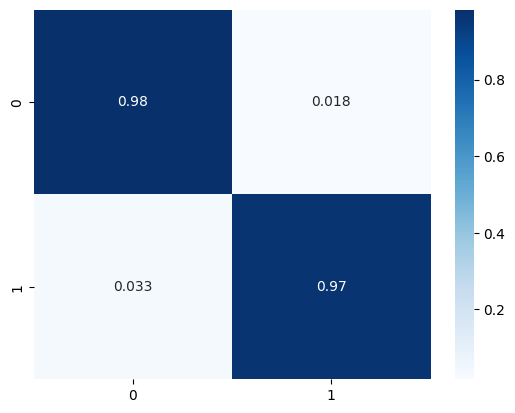

In [45]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

## Resnet101 Training

In [13]:
from torchvision.models import ResNet101_Weights as weights
transforms = weights.DEFAULT.transforms(antialias=True)
train=FoodDataset(train_df)
test=FoodDataset(test_df)
train_loader = DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
test_loader = DataLoader(test,batch_size=BATCH_SIZE,shuffle=True) 

In [14]:
model = Res50(models.resnet101(weights='IMAGENET1K_V1')).to(device)

Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:00<00:00, 189MB/s]  


In [15]:
model.train()

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:1
Training:[loss:0.4222,accuracy:82.900],
 Validation:[loss:0.3627,accuracy:93.268]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch:4
Training:[loss:0.2850,accuracy:97.151],
 Validation:[loss:0.2796,accuracy:96.816]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:5
Training:[loss:0.2712,accuracy:97.548],
 Validation:[loss:0.2695,accuracy:97.117]


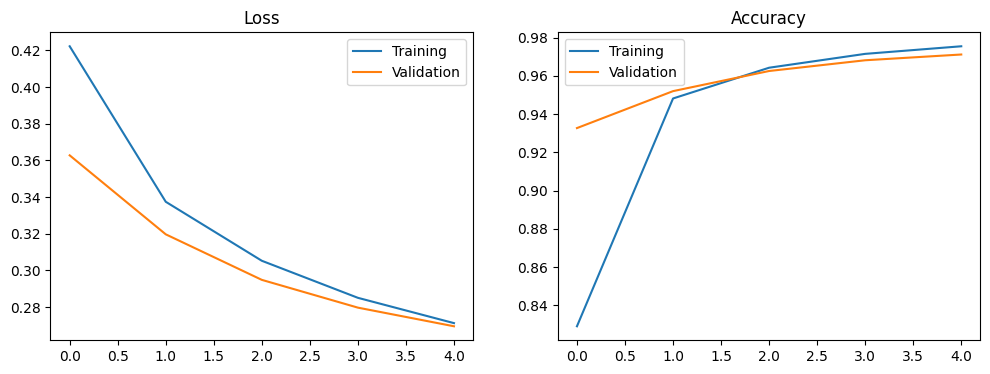

In [16]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

In [17]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)

  0%|          | 0/106 [00:00<?, ?it/s]

NameError: name 'sns' is not defined

<Axes: >

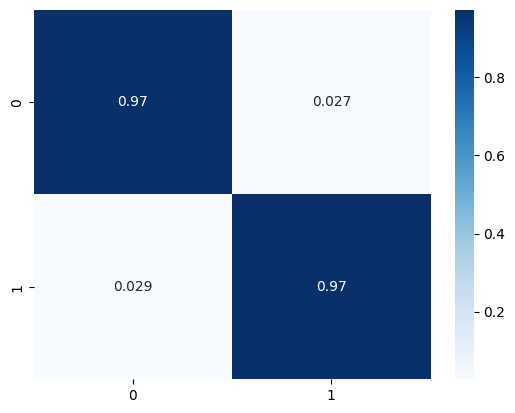

In [19]:
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

## Resnet152 Training

In [23]:
from torchvision.models import ResNet152_Weights as weights
transforms = weights.DEFAULT.transforms(antialias=True)
train=FoodDataset(train_df)
test=FoodDataset(test_df)
train_loader = DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
test_loader = DataLoader(test,batch_size=BATCH_SIZE,shuffle=True) 

In [24]:
model = Res50(models.resnet152(weights='IMAGENET1K_V1')).to(device)

In [25]:
model.train()

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:1
Training:[loss:0.4200,accuracy:80.747],
 Validation:[loss:0.3604,accuracy:90.971]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

... (6 outputs left out)

Epoch:4
Training:[loss:0.2851,accuracy:96.806],
 Validation:[loss:0.2779,accuracy:96.572]


  0%|          | 0/370 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

Epoch:5
Training:[loss:0.2679,accuracy:97.606],
 Validation:[loss:0.2642,accuracy:96.816]


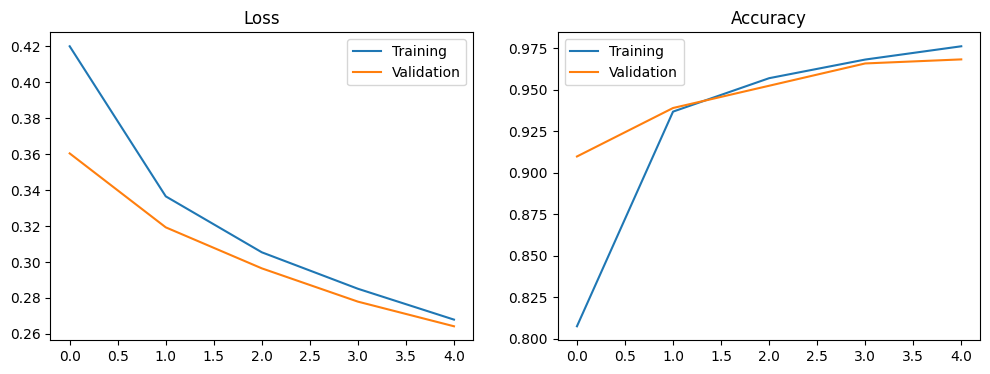

In [26]:
fig = plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.title("Loss")
plt.plot(model.history['train_loss'],label="Training")
plt.plot(model.history['val_loss'],label="Validation")
plt.legend()
plt.subplot(1,2,2)
plt.title("Accuracy")
plt.plot(model.history['train_acc'],label="Training")
plt.plot(model.history['val_acc'],label="Validation")
plt.legend()
plt.show()

In [1]:
y_true=[]
y_pred=[]
with torch.no_grad():
    for X,y in tqdm(test_loader):
        pred = model(X.to(device))
        pred = torch.argmax(pred,axis=1).detach().cpu().numpy()
        y_true.extend(y)
        y_pred.extend(pred)
sns.heatmap(confusion_matrix(y_true,y_pred,normalize='true'),cmap='Blues',cbar=True,annot=True)

NameError: name 'torch' is not defined

## Comparison of Resnet Family Models

In [7]:
acc_df = pd.DataFrame({
    'Model': ['Resnet18','Resnet18','Resnet34','Resnet34','Resnet50','Resnet50','Resnet101','Resnet101','Resnet152','Resnet152'],
    'Accuracy':[99.155,99.44,99.742,99.564,97.736,96.955,97.548,97.117,97.606,96.816],
    'Step':['Training','Validation','Training','Validation','Training','Validation','Training','Validation','Training','Validation',],
})

In [8]:
acc_df.pivot(index='Model',columns='Step',values='Accuracy')

Step,Training,Validation
Model,,
Resnet101,97.548,97.117
Resnet152,97.606,96.816
Resnet18,99.155,99.440
Resnet34,99.742,99.564
Resnet50,97.736,96.955


In [13]:
px.bar(acc_df.round(2),x='Model',y='Accuracy',color='Step',barmode='group',text_auto=True).show('iframe')